# Simulación de escenarios críticos (workshop de la semana 5)
**Proyecto:** Predicción de matrícula y continuidad estudiantil · Unidad Educativa LEMAS
**Integrantes:** Guillermo Granizo y José Ulloa · Maestría en Inteligencia Artificial (UEES)

**Pregunta guía:** ¿hasta qué nivel de perturbación la lista sigue siendo útil, y qué hace el sistema cuando deja de serlo?

| Escenario del workshop | Versión realista para LEMAS | Qué se mide |
|---|---|---|
| Ruido en la entrada | Errores de digitación en el Excel: se invierte el pago tardío o el tipo de reserva, o los atrasos se corren en uno, con probabilidad 1 % a 20 %. Ruido gaussiano solo en el promedio (variable continua de la logística híbrida) | Caída del Lift@k |
| Datos faltantes | Del 10 % al 50 % de una señal llega vacía, una señal por vez | Degradación por señal |
| Desbalance extremo | Se quitan familias con caso hasta una tasa del 5 %, 3 % y 1 % | Lift@k, Recall@k y PR-AUC |
| Cambio de distribución | La logística híbrida se entrena con una sede (o con los no becados) y se prueba con la otra (o con los becados) | PR-AUC, ROC-AUC y calibración |
| Feature clave caída | Una señal llega constante: toda en cero o toda «en plazo» | Lift@k y Recall@k |

**Reglas:** se perturba solo **C4**, con el sistema ya elegido (la regla D2 y la logística híbrida entrenada con C2 + C3, como en la Fase 2). **C5 no interviene.** No se usa F1: la lista ordena con capacidad fija (k = 165 familias), no clasifica con un umbral. Cada nivel se repite varias veces con otra perturbación y otro sorteo de empates; se guardan solo **agregados** (medias y percentiles), nunca datos individuales.

In [1]:
# @title 0 · Preparar el entorno (ejecutar primero)
# Si el repositorio ya está en GitHub, pegue su URL; si no, se pedirá subir el .zip.
REPO_URL = "https://github.com/ggranizo2507/prediccion-matricula-lemas.git"  # @param {type:"string"}

import importlib.util, os, subprocess, sys, zipfile
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/prediccion-matricula-lemas")
    if not RAIZ.exists():
        if REPO_URL:
            subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=True)
        else:
            from google.colab import files
            print("Suba el archivo prediccion-matricula-lemas.zip")
            nombre = next(iter(files.upload()))
            zipfile.ZipFile(nombre).extractall("/content")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
REQUERIDOS = {'pandas': 'pandas', 'sklearn': 'scikit-learn', 'yaml': 'PyYAML',
              'optuna': 'optuna', 'matplotlib': 'matplotlib'}  # módulo -> paquete pip
faltan = [pip for modulo, pip in REQUERIDOS.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
print("Entorno:", "Google Colab" if EN_COLAB else "local")

Entorno: Google Colab


In [2]:
# @title Cargar la base
FUENTE = "real"  # @param ["sintetica", "real"]
SUBIR_DE_NUEVO = False  # @param {type:"boolean"}

import json, logging, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
import numpy as np
import pandas as pd
from IPython.display import display
from src.data_processing import construir_dataset, limpiar_base
from src.utils import cargar_config, configurar_logging, obtener_base_seud

configurar_logging(logging.WARNING)
config = cargar_config()
SEMILLA = config["proyecto"]["semilla"]
MIN = config["privacidad"]["min_celda"]
REPETICIONES = config["escenarios"]["repeticiones"]
UMBRAL = config["escenarios"]["umbral_lift"]
ruta = RAIZ / config["rutas"]["base_real" if FUENTE == "real" else "base_sintetica"]
crudo = (obtener_base_seud(ruta, EN_COLAB, SUBIR_DE_NUEVO) if FUENTE == "real"
         else pd.read_csv(ruta, dtype=str))
dataset, _ = construir_dataset(limpiar_base(crudo, config), config)
print(f"Fuente: {FUENTE} | estudiantes modelables: {len(dataset)} | repeticiones por nivel: {REPETICIONES}")
if FUENTE == "sintetica":
    print("⚠️ Datos SINTÉTICOS: sirven para probar el código, no describen a LEMAS.")

Suba base_seud.csv (generado por 00a_seudonimizacion)


Saving base_seud.csv to base_seud.csv


Fuente: real | estudiantes modelables: 6361 | repeticiones por nivel: 50


In [3]:
# @title Sistema ya elegido y cohorte C4 (sin C5)
from src import diagnostico as dg
from src import escenarios as es
from src.evaluate import calcular_k_por_sede, consolidar_familias

n = dg.numero
MET = RAIZ / config["rutas"]["metricas"]; MET.mkdir(parents=True, exist_ok=True)
FIG = RAIZ / config["rutas"]["figuras"]; FIG.mkdir(parents=True, exist_ok=True)
DPI = config["figuras"]["dpi"]

decision = json.loads((MET / f"decision_c1_{FUENTE}.json").read_text(encoding="utf-8"))
COHORTES = config["auditoria"]["configuraciones_entrenamiento"]["con_C1" if decision["incluir_C1"] else "sin_C1"]
K = decision["k_por_sede"]
PARAMS = dg.mejores_parametros(pd.read_csv(MET / f"optuna_historial_{FUENTE}.csv"))["hibrido"]

usadas = dg.sin_prueba(dataset)                   # C5 fuera
ENTRENAMIENTO = usadas[usadas["cohorte"].isin(COHORTES)]
C4 = usadas[usadas["rol"] == "seleccion"]
HIBRIDO = es.entrenar_hibrido(ENTRENAMIENTO, PARAMS, SEMILLA)
SISTEMAS = {es.REGLA: es.puntuador_d2, es.HIBRIDO: es.puntuador_modelo(HIBRIDO)}

# Comprobación: sin perturbar y con la semilla fija se reproducen las cifras de la Fase 2 en C4
COMPROBACION = {nombre: es.medir(C4, f, K, SEMILLA) for nombre, f in SISTEMAS.items()}
print("Entrenamiento:", COHORTES, "| Perturbaciones sobre: C4 | C5: no se usa | k por sede:", K)
print("Hiperparámetros de la logística híbrida (Fase 2):", PARAMS)
display(pd.DataFrame(COMPROBACION).T.round(4))
ruta_seleccion = MET / f"seleccion_C4_{FUENTE}.csv"
if ruta_seleccion.exists():
    fase2 = pd.read_csv(ruta_seleccion).set_index("candidato")["lift_k"]
    print("Lift@k en la Fase 2:", {k: round(float(v), 4) for k, v in fase2.items()
                                    if k.startswith(("D2", "Logística híbrida"))})

Entrenamiento: ['C2', 'C3'] | Perturbaciones sobre: C4 | C5: no se usa | k por sede: {'Mucho Lote 1': 118, 'Mucho Lote 2': 47}
Hiperparámetros de la logística híbrida (Fase 2): {'balanceado': True, 'C': 9.013186751477164}


,lift_k,recall_k,precision_k,pr_auc,brier
D2 · señales administrativas,1.9278,0.3053,0.1758,0.1367,NaN
Logística híbrida,1.5289,0.2421,0.1394,0.1252,0.2196


Lift@k en la Fase 2: {'D2 · señales administrativas': 1.9278, 'Logística híbrida (señales de D2 + variables académicas)': 1.5289}


## 1 y 2. Ruido y datos faltantes
Las señales de la regla D2 son discretas: un error realista es una celda mal digitada, no un ruido gaussiano. El ruido gaussiano se aplica solo al promedio, la variable continua que usa la logística híbrida. En los faltantes, un pago tardío vacío deja al estudiante sin esa prioridad y una reserva o un atraso vacíos se leen como cero (la regla) o se imputan (el modelo).

In [4]:
# @title Errores de registro, ruido en el promedio y datos faltantes
RUIDO = es.escenario_ruido(C4, SISTEMAS, K, SEMILLA, REPETICIONES)
FALTANTES = es.escenario_faltantes(C4, SISTEMAS, K, SEMILLA, REPETICIONES)
columnas = ["variable", "sistema", "nivel", "lift_k", "lift_k_p05", "lift_k_p95", "recall_k", "pr_auc"]
display(RUIDO[columnas].round(3))
display(FALTANTES[columnas].round(3))

,variable,sistema,nivel,lift_k,lift_k_p05,lift_k_p95,recall_k,pr_auc
0,errores_registro,D2 · señales administrativas,0.00,1.768,1.595,1.928,0.280,0.137
1,errores_registro,Logística híbrida,0.00,1.529,1.529,1.529,0.242,0.125
2,errores_registro,D2 · señales administrativas,0.01,1.674,1.426,1.928,0.265,0.132
3,errores_registro,Logística híbrida,0.01,1.514,1.396,1.632,0.240,0.123
4,errores_registro,D2 · señales administrativas,0.02,1.663,1.462,1.898,0.263,0.130
5,errores_registro,Logística híbrida,0.02,1.536,1.396,1.728,0.243,0.122
6,errores_registro,D2 · señales administrativas,0.05,1.633,1.396,1.994,0.258,0.124
7,errores_registro,Logística híbrida,0.05,1.466,1.263,1.728,0.232,0.118
8,errores_registro,D2 · señales administrativas,0.10,1.484,1.226,1.802,0.235,0.116
9,errores_registro,Logística híbrida,0.10,1.332,1.094,1.662,0.211,0.112


,variable,sistema,nivel,lift_k,lift_k_p05,lift_k_p95,recall_k,pr_auc
0,pago_tardio,D2 · señales administrativas,0.0,1.768,1.595,1.928,0.280,0.137
1,pago_tardio,Logística híbrida,0.0,1.529,1.529,1.529,0.242,0.125
2,pago_tardio,D2 · señales administrativas,0.1,1.779,1.625,1.928,0.282,0.136
3,pago_tardio,Logística híbrida,0.1,1.518,1.462,1.529,0.240,0.125
4,pago_tardio,D2 · señales administrativas,0.2,1.782,1.595,1.928,0.282,0.136
5,pago_tardio,Logística híbrida,0.2,1.508,1.426,1.529,0.239,0.125
6,pago_tardio,D2 · señales administrativas,0.3,1.762,1.595,1.928,0.279,0.135
7,pago_tardio,Logística híbrida,0.3,1.494,1.396,1.529,0.237,0.124
8,pago_tardio,D2 · señales administrativas,0.4,1.751,1.559,1.928,0.277,0.133
9,pago_tardio,Logística híbrida,0.4,1.474,1.396,1.529,0.234,0.123


## 3 y 5. Desbalance extremo y señal caída
En el desbalance se quitan familias con caso (con todos sus estudiantes) hasta la tasa indicada, como en un año con muy pocas familias que no se matriculan. El k sigue siendo el aprobado. En la señal caída, la perturbación es fija y se repite solo el sorteo de empates.

In [5]:
# @title Desbalance extremo y señal caída
DESBALANCE = es.escenario_desbalance(C4, SISTEMAS, K, SEMILLA, REPETICIONES)
CAIDA = es.escenario_caida(C4, SISTEMAS, K, SEMILLA, REPETICIONES)
display(DESBALANCE[["sistema", "nivel", "tasa_real", "lift_k", "lift_k_p05", "lift_k_p95", "recall_k", "pr_auc"]].round(3))
display(CAIDA[["variable", "sistema", "lift_k", "lift_k_p05", "lift_k_p95", "recall_k", "pr_auc"]].round(3))

,sistema,nivel,tasa_real,lift_k,lift_k_p05,lift_k_p95,recall_k,pr_auc
0,D2 · señales administrativas,base,0.091,1.768,1.595,1.928,0.280,0.137
1,Logística híbrida,base,0.091,1.529,1.529,1.529,0.242,0.125
2,D2 · señales administrativas,0.05,0.050,1.847,1.384,2.242,0.306,0.083
3,Logística híbrida,0.05,0.050,1.542,1.208,1.879,0.255,0.073
4,D2 · señales administrativas,0.03,0.030,1.774,1.224,2.448,0.300,0.057
5,Logística híbrida,0.03,0.030,1.611,1.020,2.244,0.272,0.048
6,D2 · señales administrativas,0.01,0.010,1.868,0.580,2.900,0.322,0.032
7,Logística híbrida,0.01,0.010,1.520,0.580,2.639,0.262,0.024


,variable,sistema,lift_k,lift_k_p05,lift_k_p95,recall_k,pr_auc
0,ninguna,D2 · señales administrativas,1.768,1.595,1.928,0.280,0.137
1,ninguna,Logística híbrida,1.529,1.529,1.529,0.242,0.125
2,pago_tardio,D2 · señales administrativas,1.780,1.595,1.898,0.282,0.128
3,pago_tardio,Logística híbrida,1.396,1.396,1.396,0.221,0.117
4,reserva_extraordinaria,D2 · señales administrativas,1.747,1.662,1.831,0.277,0.118
5,reserva_extraordinaria,Logística híbrida,1.130,1.130,1.130,0.179,0.113
6,atrasos_pension,D2 · señales administrativas,1.659,1.492,1.861,0.263,0.112
7,atrasos_pension,Logística híbrida,1.462,1.462,1.462,0.232,0.114
8,promedio,Logística híbrida,1.481,1.396,1.566,0.234,0.124
9,todas_d2,D2 · señales administrativas,1.054,0.731,1.366,0.167,0.089


## 4. Cambio de distribución
Solo la logística híbrida aprende, así que es la única que puede sufrir al cambiar de población. Para cada dirección (origen → destino) se entrena con C2 + C3 del grupo de origen, se calibra con Platt en C4 del grupo de origen y se prueba en C4 del grupo de destino. Se compara con el modelo de la Fase 2 (entrenado con todos). Los grupos con menos de 5 casos no se muestran.

In [6]:
# @title Entrenar con un subgrupo y probar con otro
CAMBIO = es.escenario_cambio(ENTRENAMIENTO, C4, PARAMS, SEMILLA, MIN)
display(CAMBIO)

,corte,origen,destino,estudiantes_destino,modelo,eventos,pr_auc,roc_auc,brier,observados_sobre_esperados
0,sede,Mucho Lote 1,Mucho Lote 2,532,transferido,39,0.0715,0.4042,0.0688,0.745
1,sede,Mucho Lote 1,Mucho Lote 2,532,referencia (todos),39,0.1830,0.6803,0.0662,0.836
2,sede,Mucho Lote 1,Mucho Lote 2,532,regla D2 (sin aprendizaje),39,0.1343,0.6556,NaN,NaN
3,sede,Mucho Lote 2,Mucho Lote 1,842,transferido,83,0.1652,0.5711,0.0884,1.266
4,sede,Mucho Lote 2,Mucho Lote 1,842,referencia (todos),83,0.1123,0.5399,0.0891,1.101
5,sede,Mucho Lote 2,Mucho Lote 1,842,regla D2 (sin aprendizaje),83,0.1434,0.5732,NaN,NaN
6,beca,0,1,171,transferido,13,0.2562,0.6879,0.0684,0.945
7,beca,0,1,171,referencia (todos),13,0.2664,0.6962,0.0682,0.964
8,beca,0,1,171,regla D2 (sin aprendizaje),13,0.3871,0.6726,NaN,NaN
9,beca,1,0,1203,transferido,109,0.1093,0.5405,0.0874,0.934


## Figuras, límites operativos y conclusiones
Un nivel de perturbación es **útil** si el Lift@k de la regla D2 sigue en 1,20 o más (la meta del proyecto y el umbral de alerta), tanto en la media como en el percentil 5 de las repeticiones.

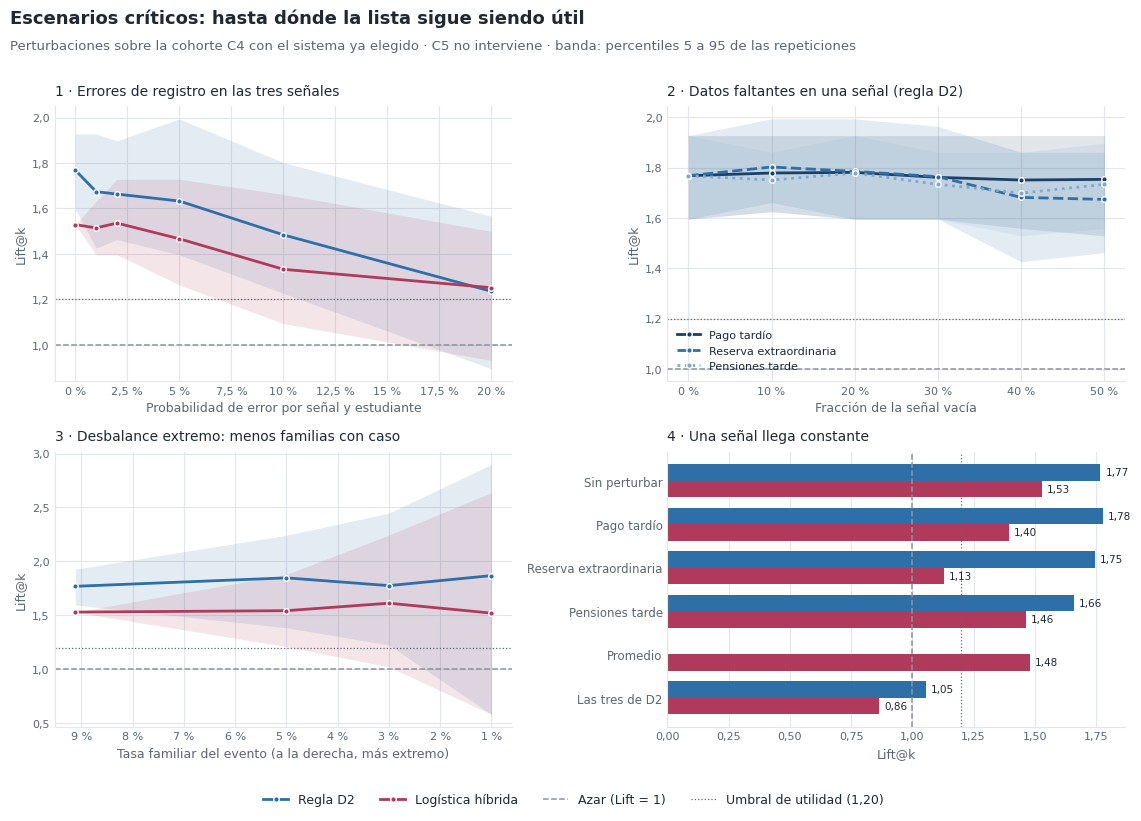

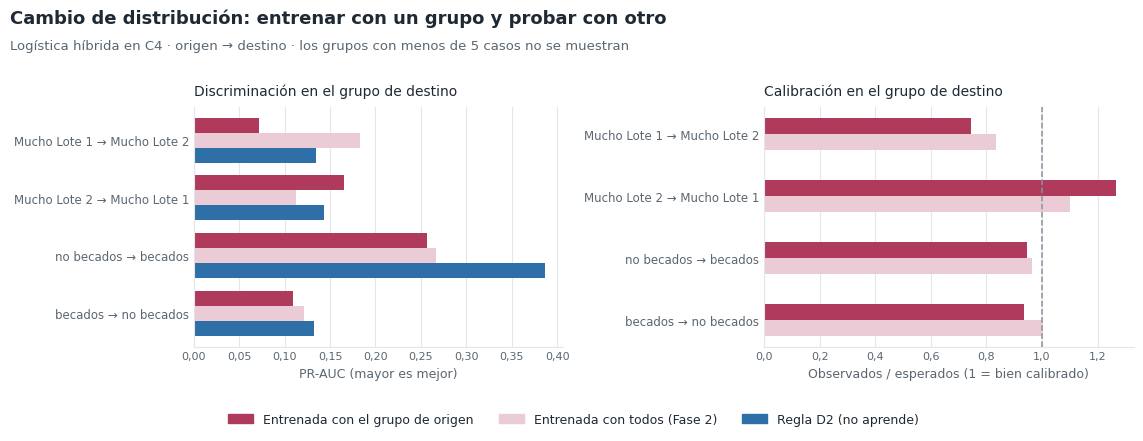

,escenario,variable,sistema,umbral_lift,ultimo_nivel_util,primer_nivel_no_util,lift_base
0,ruido,errores_registro,D2 · señales administrativas,1.2,0.1,0.2,1.7682
1,faltantes,pago_tardio,D2 · señales administrativas,1.2,0.5,None,1.7682
2,faltantes,reserva_extraordinaria,D2 · señales administrativas,1.2,0.5,None,1.7682
3,faltantes,atrasos_pension,D2 · señales administrativas,1.2,0.5,None,1.7682
4,desbalance,tasa_familiar,D2 · señales administrativas,1.2,0.03,0.01,1.7682
5,senal_caida,pago_tardio,D2 · señales administrativas,1.2,constante,None,1.7802
6,senal_caida,reserva_extraordinaria,D2 · señales administrativas,1.2,constante,None,1.7470
7,senal_caida,atrasos_pension,D2 · señales administrativas,1.2,constante,None,1.6592
8,senal_caida,todas_d2,D2 · señales administrativas,1.2,None,constante,1.0543


• Sin perturbar, la regla D2 tiene en C4 un Lift@k de 1,77 y un Recall@k de 28 %.
• La lista tolera errores de registro hasta el 10 % de las filas; desde el 20 % cae bajo el umbral.
• Con hasta el 50 % de vacíos en pago tardío de la matrícula anterior, la lista sigue siendo útil.
• Con hasta el 50 % de vacíos en reserva extraordinaria, la lista sigue siendo útil.
• Con hasta el 50 % de vacíos en pensiones pagadas tarde, la lista sigue siendo útil.
• Si la señal «pago tardío de la matrícula anterior» llega constante, el Lift@k pasa a 1,78 (Recall@k 28 %).
• Si la señal «reserva extraordinaria» llega constante, el Lift@k pasa a 1,75 (Recall@k 28 %).
• Si la señal «pensiones pagadas tarde» llega constante, el Lift@k pasa a 1,66 (Recall@k 26 %).
• Si las tres señales llegan constantes, el Lift@k pasa a 1,05 (Recall@k 17 %).
• Con una tasa familiar del 5 %, el Lift@k medio es 1,85 (del 1,38 al 2,24 según qué familias queden).
• Con una tasa familiar del 3 %, el Lift@k medio es 1,77 (del 1,2

In [7]:
# @title Figuras, límites y conclusiones
import matplotlib.pyplot as plt
from src import graficos_escenarios as ge

RESULTADOS = pd.concat([RUIDO, FALTANTES, DESBALANCE, CAIDA], ignore_index=True)
fig = ge.figura_degradacion(RESULTADOS, "C4", UMBRAL)
ge.guardar(fig, FIG / f"{FUENTE}_29_escenarios_criticos.png", DPI); plt.show()
if not CAMBIO.empty:
    fig = ge.figura_cambio(CAMBIO)
    ge.guardar(fig, FIG / f"{FUENTE}_30_cambio_distribucion.png", DPI); plt.show()

LIMITES = es.limites(RESULTADOS, UMBRAL)
display(LIMITES)
CONCLUSIONES = es.conclusiones(RESULTADOS, CAMBIO, LIMITES, UMBRAL)
for frase in CONCLUSIONES:
    print("•", frase)

RESULTADOS.to_csv(MET / f"escenarios_criticos_{FUENTE}.csv", index=False, float_format="%.4f")
CAMBIO.to_csv(MET / f"escenarios_cambio_{FUENTE}.csv", index=False, float_format="%.4f")
LIMITES.to_csv(MET / f"escenarios_limites_{FUENTE}.csv", index=False)
resumen = {"fuente": FUENTE, "cohortes_entrenamiento": COHORTES, "perturbada": "C4",
           "k_por_sede": K, "repeticiones": REPETICIONES, "umbral_lift": UMBRAL,
           "parametros_hibrido": PARAMS, "comprobacion_sin_perturbar": COMPROBACION,
           "conclusiones": CONCLUSIONES}
(MET / f"escenarios_criticos_{FUENTE}.json").write_text(
    json.dumps(resumen, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("\nGuardado: escenarios_criticos, escenarios_cambio y escenarios_limites")

## Qué hace el sistema cuando deja de ser útil
- **Al generar la lista**, la aplicación revisa las señales del ciclo cargado (`inferencia.revisar_senales`): si casi todos figuran como nuevos (falta la hoja anterior), si falta la fecha de pago en más del 20 % de los que no son nuevos, si los atrasos llegan vacíos o todos en cero, o si el tipo de reserva está vacío. En esos casos muestra un aviso en rojo y pide corregir el Excel antes de usar la lista. Los umbrales están en `config.yaml` (`calidad_senales`) y se revisan con los límites de este cuaderno.
- **Cada mayo**, con el resultado de la campaña, se recalcula el Lift@k de la lista. Si baja de 1,20, se activa la alerta y quien designe la Dirección decide si se suspende el uso (decisión 5 de la presentación a la Dirección).
- Detalle en `docs/escenarios_criticos.md`.

In [8]:
# @title Descargar agregados para compartir (Colab)
# Solo métricas y figuras agregadas: no contiene datos individuales.
import shutil
paquete = RAIZ / f"escenarios_{FUENTE}"
shutil.rmtree(paquete, ignore_errors=True); paquete.mkdir()
for nombre in [f"escenarios_criticos_{FUENTE}.csv", f"escenarios_cambio_{FUENTE}.csv",
               f"escenarios_limites_{FUENTE}.csv", f"escenarios_criticos_{FUENTE}.json"]:
    shutil.copy(MET / nombre, paquete)
for png in sorted(FIG.glob(f"{FUENTE}_29_*.png")) + sorted(FIG.glob(f"{FUENTE}_30_*.png")):
    shutil.copy(png, paquete)
zip_final = shutil.make_archive(str(paquete), "zip", paquete)
shutil.rmtree(paquete)
print("Contenido:", sorted(zipfile.ZipFile(zip_final).namelist()))
if EN_COLAB:
    from google.colab import files
    files.download(zip_final)

Contenido: ['escenarios_cambio_real.csv', 'escenarios_criticos_real.csv', 'escenarios_criticos_real.json', 'escenarios_limites_real.csv', 'real_29_escenarios_criticos.png', 'real_30_cambio_distribucion.png']
